# Topic Modeling: Public Reaction to AI-Related Short-Form Video Content
**Data:** YouTube and TikTok comments | **Models:** LDA (gensim) and BERTopic | **Metrics:** c_v, u_mass, held-out perplexity, topic diversity

Pipeline: load, filter, preprocess, explore, 90/10 split, LDA (choose k by coherence), evaluate, visualize, BERTopic, compare, topic-by-platform.

In [1]:
!pip install -q gensim pyLDAvis bertopic sentence-transformers umap-learn hdbscan langdetect
# Running locally on Python 3.14? gensim has no 3.14 wheel yet, so install it from git instead:
# !pip install git+https://github.com/RaRe-Technologies/gensim.git

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 5.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 44.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 64.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 9.4 MB/s eta 0:00:00


## 1. Imports and settings

In [6]:
import json, re, warnings
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from langdetect import detect, DetectorFactory
from sklearn.model_selection import train_test_split
from gensim.corpora import Dictionary
from gensim.models import LdaModel, CoherenceModel
from gensim.models.phrases import Phrases

warnings.filterwarnings("ignore")
SEED = 42
DetectorFactory.seed = SEED
DATA_PATH = "preprocessed_dataset.csv"
MAX_PER_VIDEO = 100      # cap so no single video dominates the topics
MIN_TOKENS = 3           # minimum tokens per comment after cleaning

## 2. Load data

In [11]:
try:
    from google.colab import files
    IN_COLAB = True
    import os
    if not os.path.exists(DATA_PATH):
        files.upload()          # choose preprocessed_dataset.csv
except ImportError:
    IN_COLAB = False

df = pd.read_csv(DATA_PATH, encoding="utf-8")
print("Loaded:", df.shape)
print(df["platform"].value_counts())
df[["platform", "original_text", "clean_text"]].head()

Loaded: (2783, 14)
platform
TikTok     2057
YouTube     726
Name: count, dtype: int64


,platform,original_text,clean_text
0,YouTube,Finaly a straight to the point shortfilm. No d...,finaly straight shortfilm dragged dialogues
1,YouTube,For real I hate that shit lol,real hate shit lol
2,YouTube,Aw he loved her before she lost weight,loved lost weight
3,YouTube,Am just loving the wife and also how she prote...,loving wife protect kids treated kid
4,YouTube,Cracks me up that they every name but DeMarco 😂,cracks demarco


## 3. Filtering
Steps: drop duplicate comments, drop very short comments, keep English/Tagalog only (the TikTok data contains a lot of Italian), cap comments per video.

In [12]:
n0 = len(df)
df = df.drop_duplicates("clean_text")
df = df[df["clean_text"].str.split().str.len() >= MIN_TOKENS]
n1 = len(df)

def lang(t):
    try:
        return detect(t)
    except Exception:
        return "unk"

df["lang"] = df["original_text"].apply(lang)
print(df["lang"].value_counts().head(8))
df = df[df["lang"].isin(["en", "tl"])]
n2 = len(df)

df = (df.sample(frac=1, random_state=SEED)            # shuffle, then keep up to N per video
        .groupby("content_id").head(MAX_PER_VIDEO)
        .reset_index(drop=True))
n3 = len(df)

pd.DataFrame({"step": ["start", "dedupe + min tokens", "English/Tagalog only", "cap per video"],
              "rows": [n0, n1, n2, n3]})

lang
en    1069
tl      32
it       5
nl       3
da       2
et       2
es       2
id       2
Name: count, dtype: int64


,step,rows
0,start,2783
1,dedupe + min tokens,1126
2,English/Tagalog only,1101
3,cap per video,904


## 4. Preprocessing for topic modeling
Here we remove domain stopwords (filler such as "next part please") and tokenize.

In [13]:
STOP = {
    # AI terms that appear everywhere
    "ai", "artificial", "intelligence", "chatgpt", "gpt",
    # platform and request filler
    "next", "part", "episode", "please", "pls", "plz", "movie", "channel", "subscribe",
    "thank", "thanks", "watch", "watching", "watched", "full", "drama", "video", "videos",
    "like", "just", "really", "one", "get", "can", "don", "will", "now", "make", "made",
    # common Taglish fillers
    "ang", "ng", "na", "sa", "mga", "po", "ako", "ka", "ko", "naman", "lang", "yung",
    "din", "ba", "pa", "kasi", "talaga",
    # emoji names, platform names and Pidgin fillers seen in the data
    "red", "heart", "joy", "face", "tiktok", "instagram", "facebook", "youtube",
    "https", "www", "dey", "abeg", "yae",
}

def tokenize(text):
    return [w for w in re.findall(r"[a-z']+", text.lower()) if w not in STOP and len(w) > 2]

df["tokens"] = df["clean_text"].apply(tokenize)
df = df[df["tokens"].str.len() >= 2].reset_index(drop=True)
print("Rows after stopword removal:", len(df))
df[["clean_text", "tokens"]].head()

Rows after stopword removal: 881


,clean_text,tokens
0,god hour acting weak mortals melodrama complet...,"[god, hour, acting, weak, mortals, melodrama, ..."
1,noticed disappointed cos lost drama watching u...,"[noticed, disappointed, cos, lost, update, hap..."
2,watched 45min advert skip,"[min, advert, skip]"
3,god bless protect,"[god, bless, protect]"
4,alike costumes fantastic strides amazing,"[alike, costumes, fantastic, strides, amazing]"


## 5. Data exploration

          count  mean  std  min  25%  50%  75%   max
platform                                            
TikTok    645.0   4.6  2.8  2.0  3.0  4.0  5.0  27.0
YouTube   236.0   5.5  5.5  2.0  3.0  4.0  6.0  72.0

Comments per video (top 5):
content_id
7482999322599181614    100
n9D3b0K9pko             99
7686339862995291422     70
7469458353190636805     64
UASLAWHqKJA             50
dtype: int64


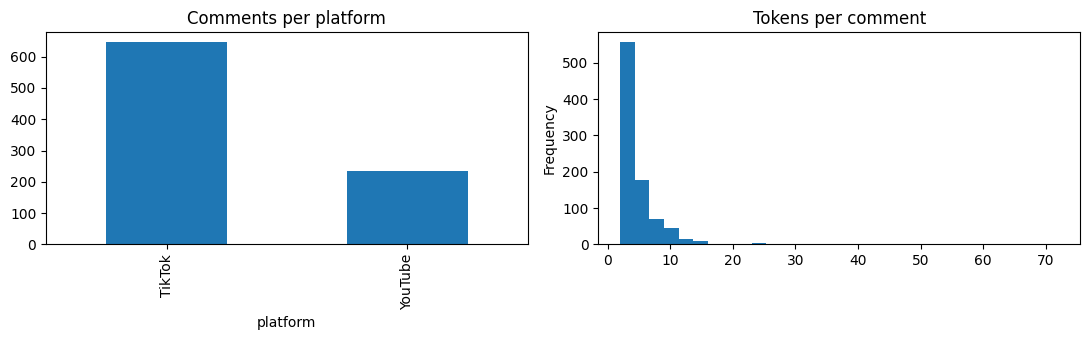

YouTube [('story', 24), ('love', 21), ('user', 12), ('lol', 11), ('time', 11), ('loved', 10), ('god', 9), ('bro', 9), ('amazing', 8), ('people', 8), ('rest', 8), ('water', 8), ('funny', 7), ('stupid', 7), ('bad', 7)]
TikTok [('love', 44), ('people', 38), ('tears', 26), ('story', 22), ('god', 21), ('girl', 20), ('time', 19), ('real', 15), ('girls', 15), ('feel', 15), ('person', 15), ('user', 15), ('life', 14), ('woman', 14), ('straight', 14)]


In [14]:
df["n_tokens"] = df["tokens"].str.len()
print(df.groupby("platform")["n_tokens"].describe().round(1))
print("\nComments per video (top 5):")
print(df.groupby("content_id").size().sort_values(ascending=False).head())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df["platform"].value_counts().plot.bar(ax=ax[0], title="Comments per platform")
df["n_tokens"].plot.hist(bins=30, ax=ax[1], title="Tokens per comment")
plt.tight_layout(); plt.show()

from collections import Counter
for p in df["platform"].unique():
    c = Counter(w for t in df[df.platform == p]["tokens"] for w in t)
    print(p, c.most_common(15))

## 6. Train/holdout split (90/10)
The 10% holdout is unseen data for validation; it is also used for held-out perplexity.

In [15]:
train_df, hold_df = train_test_split(df, test_size=0.10, random_state=SEED, stratify=df["platform"])
train_df, hold_df = train_df.reset_index(drop=True), hold_df.reset_index(drop=True)
print("Train:", len(train_df), "| Holdout:", len(hold_df))

Train: 792 | Holdout: 89


## 7. Bigrams, dictionary, corpus

In [16]:
train_tokens = train_df["tokens"].tolist()
hold_tokens = hold_df["tokens"].tolist()

bigram = Phrases(train_tokens, min_count=3, threshold=10).freeze()
train_tokens = [bigram[d] for d in train_tokens]
hold_tokens = [bigram[d] for d in hold_tokens]

dictionary = Dictionary(train_tokens)
dictionary.filter_extremes(no_below=2, no_above=0.6)
train_corpus = [dictionary.doc2bow(d) for d in train_tokens]
hold_corpus = [dictionary.doc2bow(d) for d in hold_tokens]
print("Vocabulary size:", len(dictionary))

Vocabulary size: 591


## 8. Choose the number of topics (k) by c_v coherence

3 0.6503
4 0.6339
5 0.6347
6 0.6449
7 0.6403
8 0.6456
9 0.6322
10 0.6445


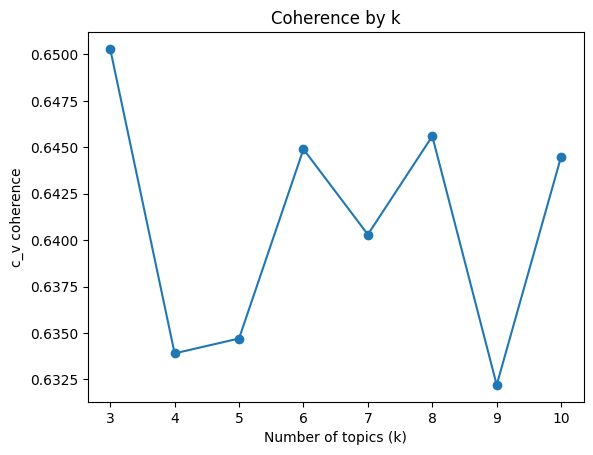

,k,c_v
0,3,0.6503
1,4,0.6339
2,5,0.6347
3,6,0.6449
4,7,0.6403
5,8,0.6456
6,9,0.6322
7,10,0.6445


In [17]:
ks = list(range(3, 11))
rows = []
for k in ks:
    m = LdaModel(train_corpus, num_topics=k, id2word=dictionary, passes=10,
                 random_state=SEED, alpha="auto", eta="auto")
    cv = CoherenceModel(model=m, texts=train_tokens, dictionary=dictionary, coherence="c_v").get_coherence()
    rows.append({"k": k, "c_v": round(cv, 4)})
    print(k, round(cv, 4))

k_table = pd.DataFrame(rows)
plt.plot(k_table["k"], k_table["c_v"], marker="o")
plt.xlabel("Number of topics (k)"); plt.ylabel("c_v coherence"); plt.title("Coherence by k"); plt.show()
k_table

## 9. Final LDA model

In [18]:
best_k = int(k_table.loc[k_table["c_v"].idxmax(), "k"])
print("Selected k =", best_k)

lda = LdaModel(train_corpus, num_topics=best_k, id2word=dictionary, passes=20,
               random_state=SEED, alpha="auto", eta="auto")
for i in range(best_k):
    print(f"Topic {i}:", ", ".join(w for w, _ in lda.show_topic(i, 10)))

Selected k = 3
Topic 0: life, love, cute, funny, trust, lol, person, literally, ooo, happy_birthday
Topic 1: people, love, user, god, bro, bad, real, time, dramas, montoya
Topic 2: story, girl, time, loved, hard, rest, love, mark, woman, amazing


## 10. Evaluation (LDA)
Note: gensim's held-out perplexity is an ELBO-based estimate and is unstable on very short comments, so treat c_v as the main metric and report perplexity with that caveat.

In [19]:
cv = CoherenceModel(model=lda, texts=train_tokens, dictionary=dictionary, coherence="c_v").get_coherence()
um = CoherenceModel(model=lda, corpus=train_corpus, dictionary=dictionary, coherence="u_mass").get_coherence()
perp = np.exp2(-lda.log_perplexity(hold_corpus))

top_words = [w for t in range(best_k) for w, _ in lda.show_topic(t, 10)]
diversity = len(set(top_words)) / len(top_words)

lda_eval = pd.DataFrame({
    "Metric": ["c_v coherence (higher better)", "u_mass coherence (closer to 0 better)",
               "Held-out perplexity (lower better)", "Topic diversity (higher better)"],
    "Value": [round(cv, 4), round(um, 4), round(perp, 2), round(diversity, 4)]})
lda_eval

,Metric,Value
0,c_v coherence (higher better),0.6521
1,u_mass coherence (closer to 0 better),-18.8369
2,Held-out perplexity (lower better),1427.6000
3,Topic diversity (higher better),0.9000


## 11. Visualization (pyLDAvis)

In [20]:
import pyLDAvis, pyLDAvis.gensim_models as gm

vis = gm.prepare(lda, train_corpus, dictionary, mds="mmds")   # mmds avoids the PCoA complex-value error
pyLDAvis.save_html(vis, "lda_vis.html")                       # file for your report
pyLDAvis.enable_notebook()
pyLDAvis.display(vis)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 12. Assign dominant topic to each comment

In [21]:
def dominant_topic(bow):
    dist = lda.get_document_topics(bow, minimum_probability=0)
    return max(dist, key=lambda x: x[1])[0]

train_df["lda_topic"] = [dominant_topic(b) for b in train_corpus]
hold_df["lda_topic"] = [dominant_topic(b) for b in hold_corpus]

topic_table = pd.DataFrame({
    "Topic": range(best_k),
    "Top words": [", ".join(w for w, _ in lda.show_topic(i, 8)) for i in range(best_k)],
    "Train docs": [(train_df["lda_topic"] == i).sum() for i in range(best_k)],
    "Holdout docs": [(hold_df["lda_topic"] == i).sum() for i in range(best_k)]
})
topic_table["Share of train %"] = (topic_table["Train docs"] / len(train_df) * 100).round(1)
topic_table

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,Topic,Top words,Train docs,Holdout docs,Share of train %
0,0,"life, love, cute, funny, trust, lol, person, l...",216,19,27.3
1,1,"people, love, user, god, bro, bad, real, time",319,34,40.3
2,2,"story, girl, time, loved, hard, rest, love, mark",257,36,32.4


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### Example comments per topic (used to label topics)

In [22]:
for i in range(best_k):
    print(f"\n--- Topic {i} ---")
    for t in train_df[train_df["lda_topic"] == i]["original_text"].head(4):
        print("  -", t[:120].replace("\n", " "))


--- Topic 0 ---
  - Go watch the Spain seasons. This is NOTHINGGG
  - check my page fors for ai movies also
  - So is he called marco de marco??
  - It hurts to say it out loud, but it is true. I feel like a good person, but I guess I am not

--- Topic 1 ---
  - How I remember those scenes from the Avatar legend of Korra... some looks hilarious
  - Abeg kill Micheal and let Cynthia enjoy in peace
  - Every clip I have seen of Montoya has been against my will, ANITA free this guy
  - That one bro who gon crack anything

--- Topic 2 ---
  - Daniel is the Michael of Billionare you dont nkow
  - I almost forget about this story sef
  - mark is a girls girl, we love mark
  - Such a deep abandonment wound she has . I’m very much like her and trying so hard to work on mine but it’s far from easy


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 12b. Topic labels (LDA)


In [23]:
lda_labels = {
    0: "Recommendations, Promo & Self-Reflection",
    1: "Character Reactions & Pop-Culture References",
    2: "Relating to Characters & Their Stories",
}

train_df["lda_label"] = train_df["lda_topic"].map(lda_labels).fillna(train_df["lda_topic"].apply(lambda x: f"Topic {x}"))
hold_df["lda_label"]  = hold_df["lda_topic"].map(lda_labels).fillna(hold_df["lda_topic"].apply(lambda x: f"Topic {x}"))

topic_table = topic_table.drop(columns=["Topic Category"], errors="ignore")
topic_table.insert(1, "Topic Category", topic_table["Topic"].map(lda_labels).fillna(topic_table["Topic"].apply(lambda x: f"Topic {x}")))
topic_table

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,Topic,Topic Category,Top words,Train docs,Holdout docs,Share of train %
0,0,"Recommendations, Promo & Self-Reflection","life, love, cute, funny, trust, lol, person, l...",216,19,27.3
1,1,Character Reactions & Pop-Culture References,"people, love, user, god, bro, bad, real, time",319,34,40.3
2,2,Relating to Characters & Their Stories,"story, girl, time, loved, hard, rest, love, mark",257,36,32.4


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 13. Topic distribution by platform

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

platform                                      TikTok  YouTube
lda_label                                                    
Character Reactions & Pop-Culture References   0.378    0.472
Recommendations, Promo & Self-Reflection       0.288    0.231
Relating to Characters & Their Stories         0.334    0.297


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

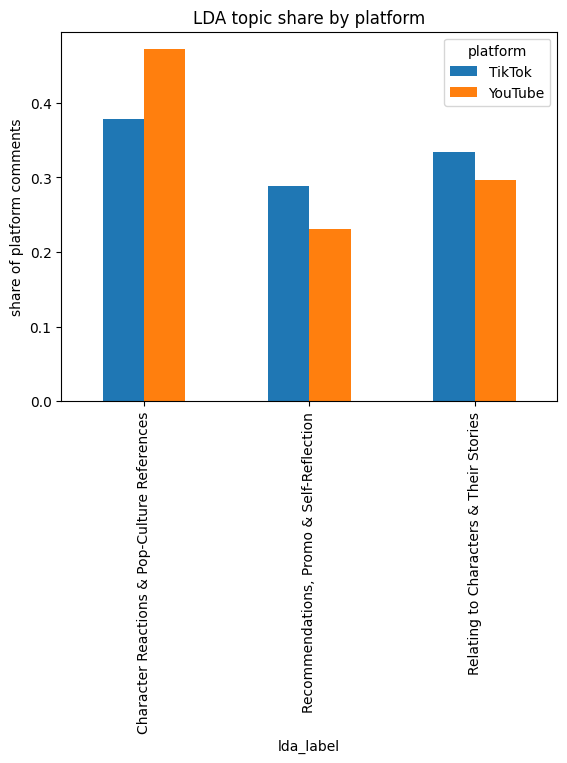

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Cosine similarity (TikTok vs YouTube topic mix): 0.9816


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [24]:
ct = pd.crosstab(train_df["lda_label"], train_df["platform"], normalize="columns").round(3)
print(ct)
ct.plot.bar(title="LDA topic share by platform"); plt.ylabel("share of platform comments"); plt.show()

# cosine similarity between the platforms' topic distributions
from numpy.linalg import norm
a, b = ct["TikTok"].values, ct["YouTube"].values
print("Cosine similarity (TikTok vs YouTube topic mix):", round(float(a @ b / (norm(a) * norm(b))), 4))

## 14. BERTopic (second model)
Uses the raw comment text and a multilingual sentence embedder, which suits short, informal, code-switched comments better than LDA. Topic `-1` holds outliers.

In [25]:
from bertopic import BERTopic
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from umap import UMAP
from hdbscan import HDBSCAN

# BERTopic reads the RAW comments, so it also needs ordinary stopwords (the, and, this, she...)
STOP_BT = STOP | set(ENGLISH_STOP_WORDS) | {
    "lng", "ntin", "yan", "ito", "mo", "ni", "si", "nang", "namin", "natin", "niya",   # Tagalog fillers
    "che", "non", "per", "con", "una", "del", "sono", "come", "della", "questo",        # Italian fillers
}

def bt_tokenize(text):
    return [w for w in re.findall(r"[a-z']+", text.lower()) if w not in STOP_BT and len(w) > 2]

emb_model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
vectorizer = CountVectorizer(tokenizer=bt_tokenize, token_pattern=None, lowercase=False)

bt = BERTopic(
    embedding_model=emb_model,
    umap_model=UMAP(n_neighbors=10, n_components=5, min_dist=0.0, metric="cosine", random_state=SEED),
    hdbscan_model=HDBSCAN(min_cluster_size=8, metric="euclidean", prediction_data=True),
    vectorizer_model=vectorizer,
    calculate_probabilities=False,
)
train_texts = train_df["original_text"].tolist()
bt_topics, _ = bt.fit_transform(train_texts)
print("Topics before reduction (excl. outliers):", len(set(bt_topics)) - (1 if -1 in bt_topics else 0))

NR_TOPICS = 10                      # merge similar topics down to about this many
bt.reduce_topics(train_texts, nr_topics=NR_TOPICS)
bt_topics = bt.topics_
train_df["bt_topic"] = bt_topics

hold_topics, _ = bt.transform(hold_df["original_text"].tolist())
hold_df["bt_topic"] = hold_topics

bt.get_topic_info()[["Topic", "Count", "Name"]]

Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replac

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

...

Streaming output truncated to the last 5000 lines.
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replac

Topics before reduction (excl. outliers): 19


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,Topic,Count,Name
0,-1,265,-1_love_man_story_people
1,0,202,0_tears_mother_real_i'm
2,1,132,1_story_good_rest_version
3,2,61,2_mark_hug_felt_love
4,3,50,3_straight_clothing_lesbian_gay
5,4,27,4_trust_love_people_leave
6,5,19,5_god_allah_cong_protect
7,6,14,6_bears_died_polar_dont
8,7,13,7_birthday_happy_higher_cake
9,8,9,8_strawberry_island_balance_bananas


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 14b. Topic labels (BERTopic)
Read the IDs and words above, then fill in `bt_labels`. Topics you leave out keep BERTopic's auto-generated name.

In [26]:
for tid in sorted(train_df["bt_topic"].unique()):
    print(f"\n--- BT topic {tid} ---")
    for t in train_df[train_df["bt_topic"] == tid]["original_text"].head(5):
        print("  -", t[:110].replace("\n", " "))


--- BT topic -1 ---
  - Daniel is the Michael of Billionare you dont nkow
  - check my page fors for ai movies also
  - How I remember those scenes from the Avatar legend of Korra... some looks hilarious
  - Abeg kill Micheal and let Cynthia enjoy in peace
  - Every clip I have seen of Montoya has been against my will, ANITA free this guy

--- BT topic 0 ---
  - Go watch the Spain seasons. This is NOTHINGGG
  - So is he called marco de marco??
  - That one bro who gon crack anything
  - It hurts to say it out loud, but it is true. I feel like a good person, but I guess I am not
  - this is NOTTT what happened plus they aren't even the mc the girl rejected him because they didn't know each o

--- BT topic 1 ---
  - I almost forget about this story sef
  - Just wondering if it was possible to get the full version of The Elf Prince is my baby Daddy?
  - Please like, comment, and subscribe to the Chanel
  - I started it on Facebook came to finish it here
  - Thank you for this drama. Plea

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [27]:
info = bt.get_topic_info()[["Topic", "Count", "Name"]]
display(info)

bt_labels = {
    -1: "ASK GROUP TOM.",
    0: "ASK GROUP TOM.",
    1: "ASK GROUP TOM.",
    2: "ASK GROUP TOM.",
    3: "ASK GROUP TOM.",
    4: "ASK GROUP TOM.",
    5: "ASK GROUP TOM.",
    6: "ASK GROUP TOM.",
    7: "ASK GROUP TOM.",
    8: "ASK GROUP TOM.",
}

auto_names = dict(zip(info["Topic"], info["Name"]))
train_df["bt_label"] = train_df["bt_topic"].map(lambda t: bt_labels.get(t, auto_names.get(t, f"Topic {t}")))
hold_df["bt_label"]  = hold_df["bt_topic"].map(lambda t: bt_labels.get(t, auto_names.get(t, f"Topic {t}")))
train_df["bt_label"].value_counts()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,Topic,Count,Name
0,-1,265,-1_love_man_story_people
1,0,202,0_tears_mother_real_i'm
2,1,132,1_story_good_rest_version
3,2,61,2_mark_hug_felt_love
4,3,50,3_straight_clothing_lesbian_gay
5,4,27,4_trust_love_people_leave
6,5,19,5_god_allah_cong_protect
7,6,14,6_bears_died_polar_dont
8,7,13,7_birthday_happy_higher_cake
9,8,9,8_strawberry_island_balance_bananas


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,count
bt_label,
ASK GROUP TOM.,792


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### BERTopic evaluation (same metrics as LDA)

In [28]:
bt_dict_tokens = [bt_tokenize(t) for t in train_texts]
bt_dict = Dictionary(bt_dict_tokens)

bt_topic_words = []
for tid in sorted(t for t in set(bt_topics) if t != -1):
    words = [w for w, _ in bt.get_topic(tid)[:10] if w in bt_dict.token2id]
    if len(words) >= 2:
        bt_topic_words.append(words)

bt_cv = CoherenceModel(topics=bt_topic_words, texts=bt_dict_tokens, dictionary=bt_dict, coherence="c_v").get_coherence()
bt_all = [w for t in bt_topic_words for w in t]
bt_div = len(set(bt_all)) / len(bt_all)
outlier_pct = round(100 * (train_df["bt_topic"] == -1).mean(), 1)

print("BERTopic topics (excl. outliers):", len(bt_topic_words))
print("c_v:", round(bt_cv, 4), "| diversity:", round(bt_div, 4), "| outliers %:", outlier_pct)
for i, w in enumerate(bt_topic_words):
    print(f"BT topic {i}:", ", ".join(w))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

BERTopic topics (excl. outliers): 9
c_v: 0.3829 | diversity: 0.9667 | outliers %: 33.5
BT topic 0: tears, mother, real, i'm, bro, bad, crying, time, ooo, feel
BT topic 1: story, good, rest, version, finally, interesting, dramas, amazing, series, house
BT topic 2: mark, hug, felt, love, girl, hard, bad, cried, oath, said
BT topic 3: straight, clothing, lesbian, gay, dress, dressing, people, women, mean, gender
BT topic 4: trust, love, people, leave, left, partner, wallahi, ppl, rejection, experience
BT topic 5: god, allah, cong, protect, deny, mohammad, cover, bible, hand, jesus
BT topic 6: bears, died, polar, dont, dam, seals, orcas, leopard, die, fine
BT topic 7: birthday, happy, higher, cake, bless, beautiful, angel, anni, celebration, celebrate
BT topic 8: strawberry, island, balance, bananas, bananito, blows, coconick, expect, almond, aubrey


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 15. Model comparison

In [29]:
pd.DataFrame({
    "Model": ["LDA", "BERTopic"],
    "Topics": [best_k, len(bt_topic_words)],
    "c_v": [round(cv, 4), round(bt_cv, 4)],
    "Topic diversity": [round(diversity, 4), round(bt_div, 4)],
    "Outlier docs %": [0.0, outlier_pct],
    "Holdout perplexity": [round(perp, 2), "n/a"],
})

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,Model,Topics,c_v,Topic diversity,Outlier docs %,Holdout perplexity
0,LDA,3,0.6521,0.9000,0.0,1427.6
1,BERTopic,9,0.3829,0.9667,33.5,n/a


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 16. Save outputs

In [30]:
train_df.drop(columns=["tokens"]).to_csv("topics_train.csv", index=False)
hold_df.drop(columns=["tokens"]).to_csv("topics_holdout.csv", index=False)
topic_table.to_csv("lda_topic_table.csv", index=False)
print("Saved. Reuse train_df['lda_topic'] / ['bt_topic'] for sentiment per topic and similarity measures.")

if IN_COLAB:   # Colab wipes its disk when the session ends, so download everything now
    for f in ["topics_train.csv", "topics_holdout.csv", "lda_topic_table.csv", "lda_vis.html"]:
        files.download(f)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Saved. Reuse train_df['lda_topic'] / ['bt_topic'] for sentiment per topic and similarity measures.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

...

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


<IPython.core.display.Javascript object>

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag